In [1]:
import pandas as pd

In [4]:
import matplotlib.pyplot as plt

In [5]:
df=pd.read_csv("C:/Users/Badmesh/Downloads/sales_data.csv")

In [6]:
df.isnull()

,OrderID,Date,Product,Category,Quantity,UnitPrice
0,False,False,False,False,False,False
1,False,False,False,False,False,False
2,False,False,False,False,False,False
3,False,False,False,False,False,False
4,False,False,False,False,False,False
...,...,...,...,...,...,...
95,False,False,False,False,False,False
96,False,False,False,False,False,False
97,False,False,False,False,False,False
98,False,False,False,False,False,False


In [7]:
df.dropna()

,OrderID,Date,Product,Category,Quantity,UnitPrice
0,1031,2026-01-01,Smartphone,Electronics,3,800
1,1100,2026-01-02,Headphones,Accessories,2,150
2,1028,2026-01-02,Laptop,Electronics,2,1200
3,1089,2026-01-02,Laptop,Electronics,3,1200
4,1023,2026-01-02,Tablet,Electronics,4,450
...,...,...,...,...,...,...
95,1026,2026-01-30,Tablet,Electronics,1,450
96,1090,2026-01-30,Headphones,Accessories,2,150
97,1049,2026-01-30,Smartwatch,Accessories,4,250
98,1046,2026-01-30,Smartwatch,Accessories,4,250


In [8]:
df.isnull().sum()

OrderID      0
Date         0
Product      0
Category     0
Quantity     0
UnitPrice    0
dtype: int64

In [9]:
df.fillna(0)

,OrderID,Date,Product,Category,Quantity,UnitPrice
0,1031,2026-01-01,Smartphone,Electronics,3,800
1,1100,2026-01-02,Headphones,Accessories,2,150
2,1028,2026-01-02,Laptop,Electronics,2,1200
3,1089,2026-01-02,Laptop,Electronics,3,1200
4,1023,2026-01-02,Tablet,Electronics,4,450
...,...,...,...,...,...,...
95,1026,2026-01-30,Tablet,Electronics,1,450
96,1090,2026-01-30,Headphones,Accessories,2,150
97,1049,2026-01-30,Smartwatch,Accessories,4,250
98,1046,2026-01-30,Smartwatch,Accessories,4,250


In [10]:
df.duplicated()

0     False
1     False
2     False
3     False
4     False
      ...  
95    False
96    False
97    False
98    False
99    False
Length: 100, dtype: bool

In [11]:
df.duplicated().sum()



np.int64(0)

In [13]:

df[df.duplicated()]




,OrderID,Date,Product,Category,Quantity,UnitPrice


In [14]:
df.drop_duplicates()

,OrderID,Date,Product,Category,Quantity,UnitPrice
0,1031,2026-01-01,Smartphone,Electronics,3,800
1,1100,2026-01-02,Headphones,Accessories,2,150
2,1028,2026-01-02,Laptop,Electronics,2,1200
3,1089,2026-01-02,Laptop,Electronics,3,1200
4,1023,2026-01-02,Tablet,Electronics,4,450
...,...,...,...,...,...,...
95,1026,2026-01-30,Tablet,Electronics,1,450
96,1090,2026-01-30,Headphones,Accessories,2,150
97,1049,2026-01-30,Smartwatch,Accessories,4,250
98,1046,2026-01-30,Smartwatch,Accessories,4,250


In [15]:
df["Date"] = pd.to_datetime(df["Date"])

In [16]:
df.head()

,OrderID,Date,Product,Category,Quantity,UnitPrice
0,1031,2026-01-01,Smartphone,Electronics,3,800
1,1100,2026-01-02,Headphones,Accessories,2,150
2,1028,2026-01-02,Laptop,Electronics,2,1200
3,1089,2026-01-02,Laptop,Electronics,3,1200
4,1023,2026-01-02,Tablet,Electronics,4,450


In [17]:
df["Sales"] = df["Quantity"] * df["UnitPrice"]


In [18]:
daily_sales = df.groupby("Date")["Sales"].sum().reset_index()

In [19]:
daily_sales = daily_sales.sort_values("Date")

In [20]:
daily_sales["Moving_Average"] = daily_sales["Sales"].rolling(window=3).mean()

In [21]:
plt.figure(figsize=(10,5))

<Figure size 1000x500 with 0 Axes>

<Figure size 1000x500 with 0 Axes>

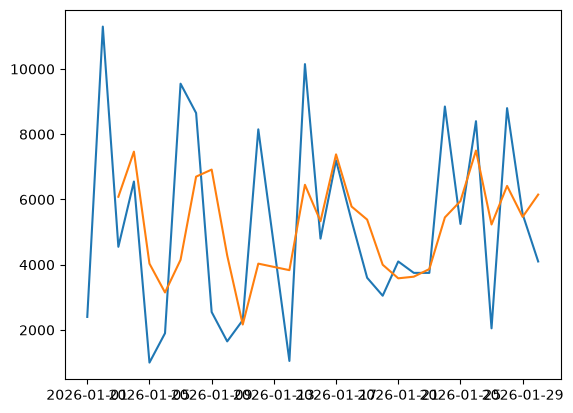

In [22]:
plt.plot(
    daily_sales["Date"],
    daily_sales["Sales"],
    label="Daily Sales"
)

plt.plot(
    daily_sales["Date"],
    daily_sales["Moving_Average"],
    label="3-Day Moving Average"
)

C:\Users\Badmesh\AppData\Local\Temp\ipykernel_11892\4145081640.py:4: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


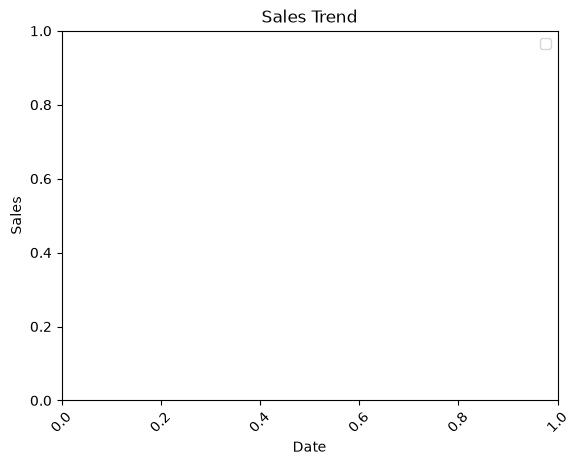

In [23]:
plt.xlabel("Date")
plt.ylabel("Sales")
plt.title("Sales Trend")
plt.legend()
plt.xticks(rotation=45)
plt.show()

In [24]:
first = daily_sales["Sales"].iloc[0]
last = daily_sales["Sales"].iloc[-1]

In [25]:
if last > first:
    print("Increasing Trend")
elif last < first:
    print("Decreasing Trend")
else:
    print("Stable Trend")

Increasing Trend
